# Армянская LLM с нуля: результаты ДЗ №1

Здесь собраны сохранённые результаты, без повторного обучения. Основной кандидат для демонстрации — **97M после continued pretraining на смеси 70% ArmWeb / 30% Wikipedia**.

Связный текст, выбор ответа из вариантов и правильный свободный ответ — разные критерии. В этом отчёте они не подменяют друг друга.

In [1]:
from pathlib import Path
from IPython.display import display, Image
import json

# Ищем комплект отчёта вместе с его рисунками.
RESULTS_DIR = next((p for p in (Path.cwd(), Path.cwd() / 'submission_results')
                    if (p / 'results.json').is_file() and (p / 'figures' / '01_pretrain_validation.png').is_file()), None)
if RESULTS_DIR is None:
    raise FileNotFoundError('Открой ноутбук из распакованного каталога submission_results')
summary = json.loads((RESULTS_DIR / 'results.json').read_text(encoding='utf-8'))

## 1. Данные

Для ArmWeb удалялись документы с повторяемостью 10-грамм выше 20% и долей армянских букв ниже 80%. Для Wikipedia удалялись служебные хвосты, применялись отдельный языковой фильтр и извлечение армянских блоков; точные дубли удалялись до разбиения на выборки. Просмотренные при настройке очистки статьи принудительно отнесены к train.

| Корпус | До очистки | После очистки | Повторы | Языковой фильтр |
| --- | --- | --- | --- | --- |
| ArmWeb train | 4 308 383 | 4 102 940 | 188 046 | 17 397 |
| Wikipedia all splits | 303 036 | 297 644 | 3 028 | — |

В первой строке только train ArmWeb, во второй — вся Wikipedia; причины пропусков в строке Wikipedia отдельно сохранены в JSON. Пересечения Wikipedia и ArmWeb не проверялись; удаление точных дублей не гарантирует отсутствия близких статей между выборками.

| Корпус | Split | Документы | Токены с BOS/EOS | Медиана длины |
| --- | --- | --- | --- | --- |
| ArmWeb | train | 4 102 940 | 1 168 571 418 | 197.0000 |
| ArmWeb | validation | 19 116 | 5 542 264 | 197.0000 |
| ArmWeb | test_iid | 19 064 | 5 560 338 | 199.0000 |
| ArmWeb | test_tail | 19 929 | 5 820 284 | 209.0000 |
| Wikipedia | train | 291 812 | 148 210 311 | 215.0000 |
| Wikipedia | validation | 2 940 | 1 666 990 | 214.0000 |
| Wikipedia | test | 2 892 | 1 414 841 | 211.5000 |

## 2. Токенизатор

Byte-level BPE обучен самостоятельно. Все четыре варианта оценены на одном validation-файле из 5000 документов; совпадение SHA256 проверено. В модель выбран словарь 16k, обученный на 500k документов. Это компромисс между длиной последовательностей и размером embedding/output-слоя; оптимальность выбора для качества модели отдельно не доказана.

| Train документов | Словарь | Символов/токен | Токенов/слово | Частота 0 в train | Частота 1–9 | Ошибок decode |
| --- | --- | --- | --- | --- | --- | --- |
| 100 000 | 16 000 | 4.7647 | 1.6235 | 69 | 60 | 0 |
| 500 000 | 8 000 | 4.2278 | 1.8297 | 50 | 10 | 0 |
| 500 000 | 16 000 | 4.7654 | 1.6233 | 50 | 20 | 0 |
| 500 000 | 32 000 | 5.2182 | 1.4824 | 57 | 69 | 0 |

Увеличение выборки со 100k до 500k при словаре 16k почти не изменило сжатие validation-текстов. На 500k уменьшилось число неиспользуемых и редких токенов; частоты при разных размерах train-выборки сами по себе несопоставимы как вероятность появления.

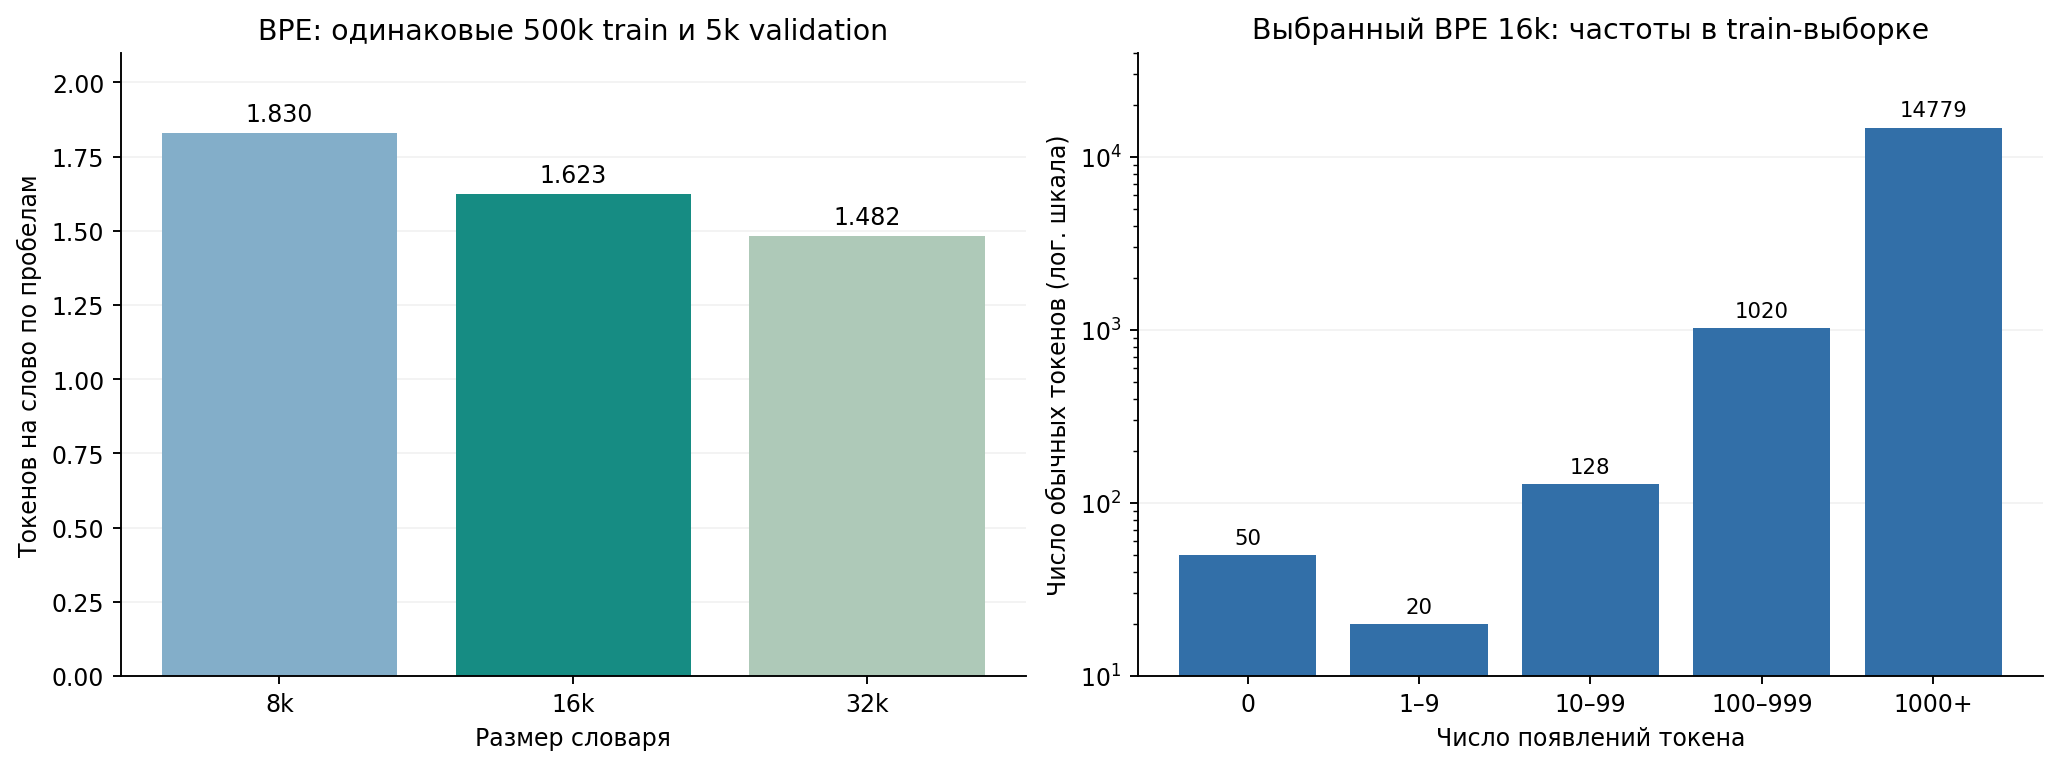

In [2]:
display(Image(filename=str(RESULTS_DIR / 'figures' / '03_tokenizers.png')))

## 3. Архитектура и запуски

Decoder-only Transformer: causal self-attention, RoPE, pre-RMSNorm, SwiGLU и общие веса входного embedding и выходной проекции. Веса и токенизатор обучены с нуля. Контекст — 1024 токена. Использованы AdamW, BF16 autocast при FP32-параметрах и Flash Attention через PyTorch SDPA; отдельный пакет Flash Attention 2 не использовался. Основной effective batch — 128 последовательностей, micro batch 32 и накопление 4.

| Модель | Параметры | Стадия | Последний шаг | План шагов | Лучший шаг | Токены стадии | Статус |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 35M | 35 463 680 | pretrain | 8 916 | 8 916 | 8 916 | 1 168 571 392 | complete |
| 97M | 97 241 856 | pretrain | 17 832 | 17 832 | 17 832 | 2 337 142 784 | complete |
| 222M · пилот | 221 938 688 | pretrain | 2 000 | 35 664 | 2 000 | 262 144 000 | pilot_complete |
| 97M + news | 97 241 856 | continued_pretrain | 1 000 | 5 000 | 0 | 131 072 000 | pilot_complete |
| 97M + mix | 97 241 856 | continued_pretrain | 5 000 | 5 000 | 5 000 | 655 360 000 | complete |
| 97M + SFT | 97 241 856 | sft | 147 | 147 | 98 | 488 718 | complete |

У SFT токены стадии — только supervised-токены ответа и EOS; их нельзя складывать с pretrain-токенами как одинаковый бюджет. Для 97M + mix суммарный pretrain — **2 992 502 784 целевых токена**, включая 2 337 142 784 токена исходной модели. **222M — пилот 2000/35664 шагов**, не завершённая четырёхэпоховая модель. Новостной контроль завершён как пилот 1000/5000; лучший checkpoint этой ветки соответствует исходному шагу 0.

| Модель | Validation для выбора | Лучший loss | Perplexity |
| --- | --- | --- | --- |
| 35M | validation | 2.8859 | 17.92 |
| 97M | validation | 2.5701 | 13.07 |
| 222M · пилот | validation | 3.0269 | 20.63 |
| 97M + news | validation_mix | 2.7553 | 15.73 |
| 97M + mix | validation_mix | 2.5853 | 13.27 |
| 97M + SFT | validation | 3.0152 | 20.39 |

У continued pretraining `validation_mix` — фиксированная сумма 0.7 × ArmWeb loss + 0.3 × Wikipedia loss; у SFT `validation` относится только к ответам. Эти столбцы не являются одним общим тестом для всех стадий.

### Кривые validation

Для недоступных CSV использован сохранённый текст outputs из `Untitled.ipynb`, с округлением loss до четырёх знаков. **35M: доступный лог до шага 8916, последний шаг обучения 8916.** **97M: доступный лог до шага 1650, последний шаг обучения 17832.** Конечная точка при отсутствии полного лога взята отдельно из `summary.json` и метаданных выбранного checkpoint; линия через отсутствующий участок не проводится. Если CSV доступны при повторном запуске сборщика, они используются автоматически.

35M обучена на 1.169 млрд токенов, 97M — на 2.337 млрд. Итоговое сравнение смешивает эффект размера и дополнительного обучения. Разница learning rate у 222M — ещё один фактор.

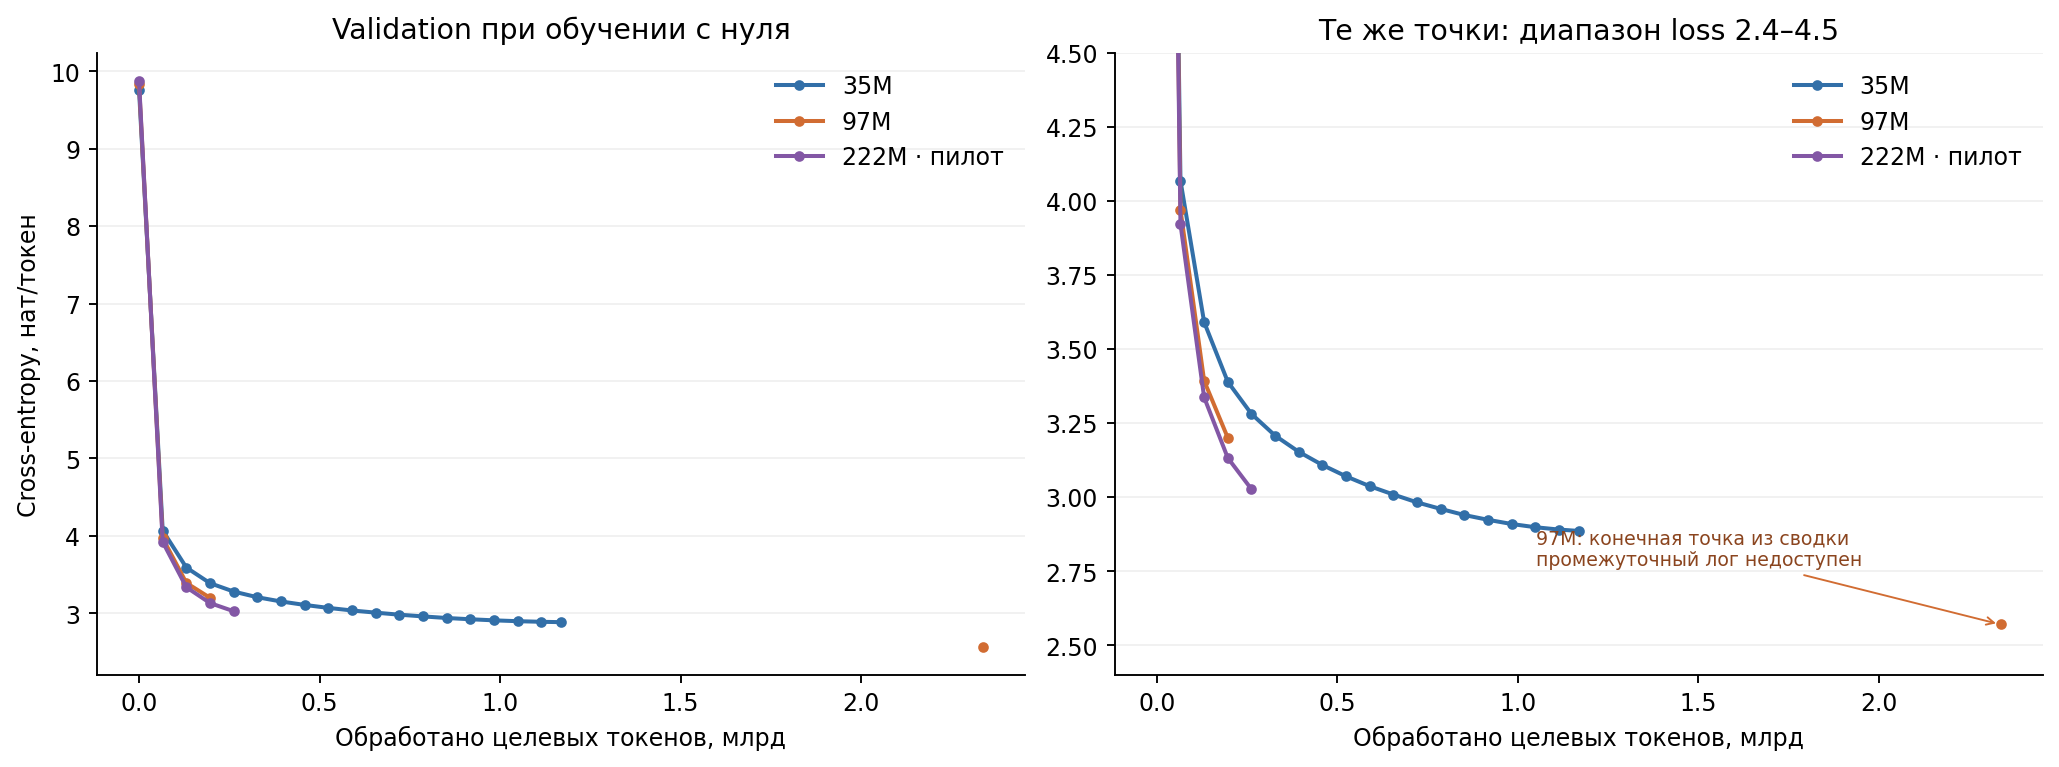

In [3]:
display(Image(filename=str(RESULTS_DIR / 'figures' / '01_pretrain_validation.png')))

### Скорость и память

| Модель | Micro batch | Накопление | Токенов/с | Пик allocated, ГиБ | Шагов замера |
| --- | --- | --- | --- | --- | --- |
| 35M | 16 | 8 | 454444.7972 | 7.9342 | 5 |
| 35M | 32 | 4 | 500496.6476 | 15.1669 | 5 |
| 35M | 64 | 2 | 471609.3720 | 29.6701 | 5 |
| 35M | 128 | 1 | 473534.5464 | 58.5371 | 5 |
| 97M | 16 | 8 | 230448.8731 | 13.3105 | 10 |
| 97M | 32 | 4 | 244777.5115 | 24.9190 | 10 |
| 97M | 64 | 2 | 237341.3383 | 48.1411 | 10 |
| 222M | 16 | 8 | 128069.4110 | 21.9376 | 10 |
| 222M | 32 | 4 | 135684.2724 | 40.0197 | 10 |

Micro batch 32 показал максимальную скорость среди протестированных вариантов для всех трёх конфигураций. Замеры короткие, без повторов и доверительных интервалов: для 35M 2 шага разогрева + 5 замеров, для 97M/222M — 3 + 10. Пик allocated отличается от зарезервированной памяти и от веса checkpoint.

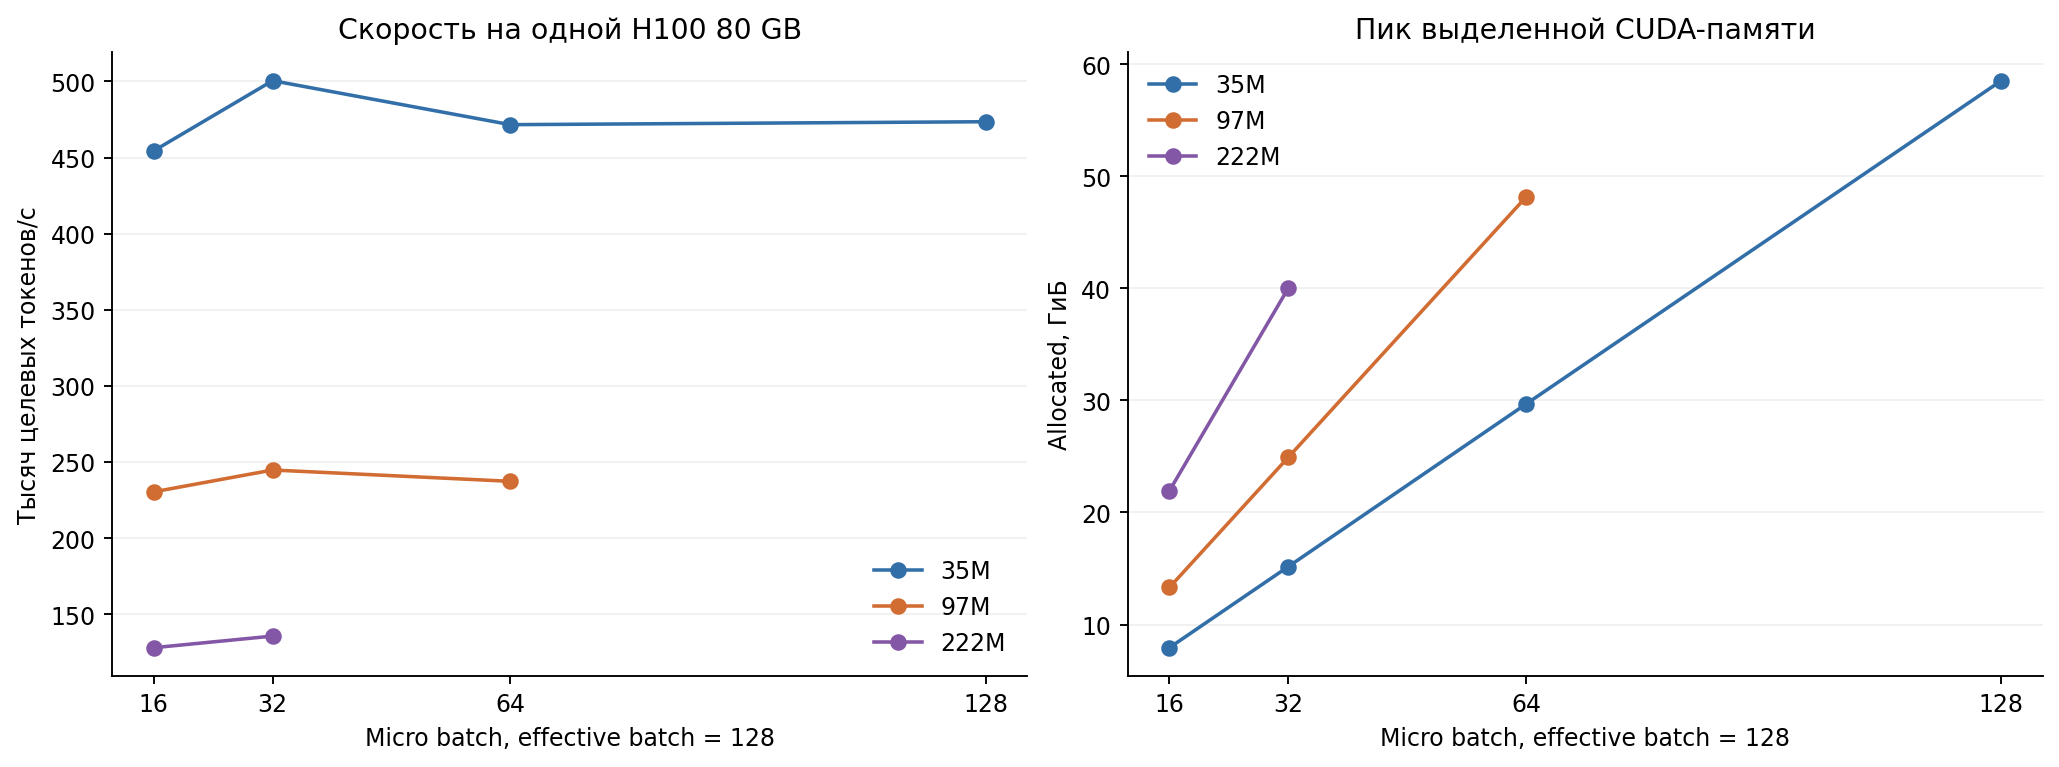

In [4]:
display(Image(filename=str(RESULTS_DIR / 'figures' / '04_batch_benchmark.png')))

## 4. Влияние Wikipedia

Обе ветки начинаются с одного checkpoint исходной 97M. В каждой заново создан AdamW, совпадают effective batch, warmup и расписание LR на 5000 шагов. Контролируемое сравнение проводится на **последнем состоянии шага 1000**, при 131 072 000 дополнительных целевых токенов в каждой ветке. Это сравнение использует сохранённые validation-метрики; checkpoint шага 1000 смеси не требуется для чтения графика.

| Ветка | Validation | Loss на шаге 1000 |
| --- | --- | --- |
| 97M + news | validation_armweb | 2.5792 |
| 97M + news | validation_wikipedia | 3.2001 |
| 97M + news | validation_mix | 2.7654 |
| 97M + mix | validation_armweb | 2.5905 |
| 97M + mix | validation_wikipedia | 2.7416 |
| 97M + mix | validation_mix | 2.6358 |

На Wikipedia смесь дала loss **2.7416** против **3.2001** у новостного контроля. На ArmWeb смесь в этой точке немного хуже: **2.5905** против **2.5792**. После 5000 шагов смеси loss составил **2.5650 / 2.6329** на ArmWeb / Wikipedia. Сравнения с новостной веткой на 5000 шагах нет. Это один запуск на seed 42; устойчивость эффекта на других seed не измерялась.

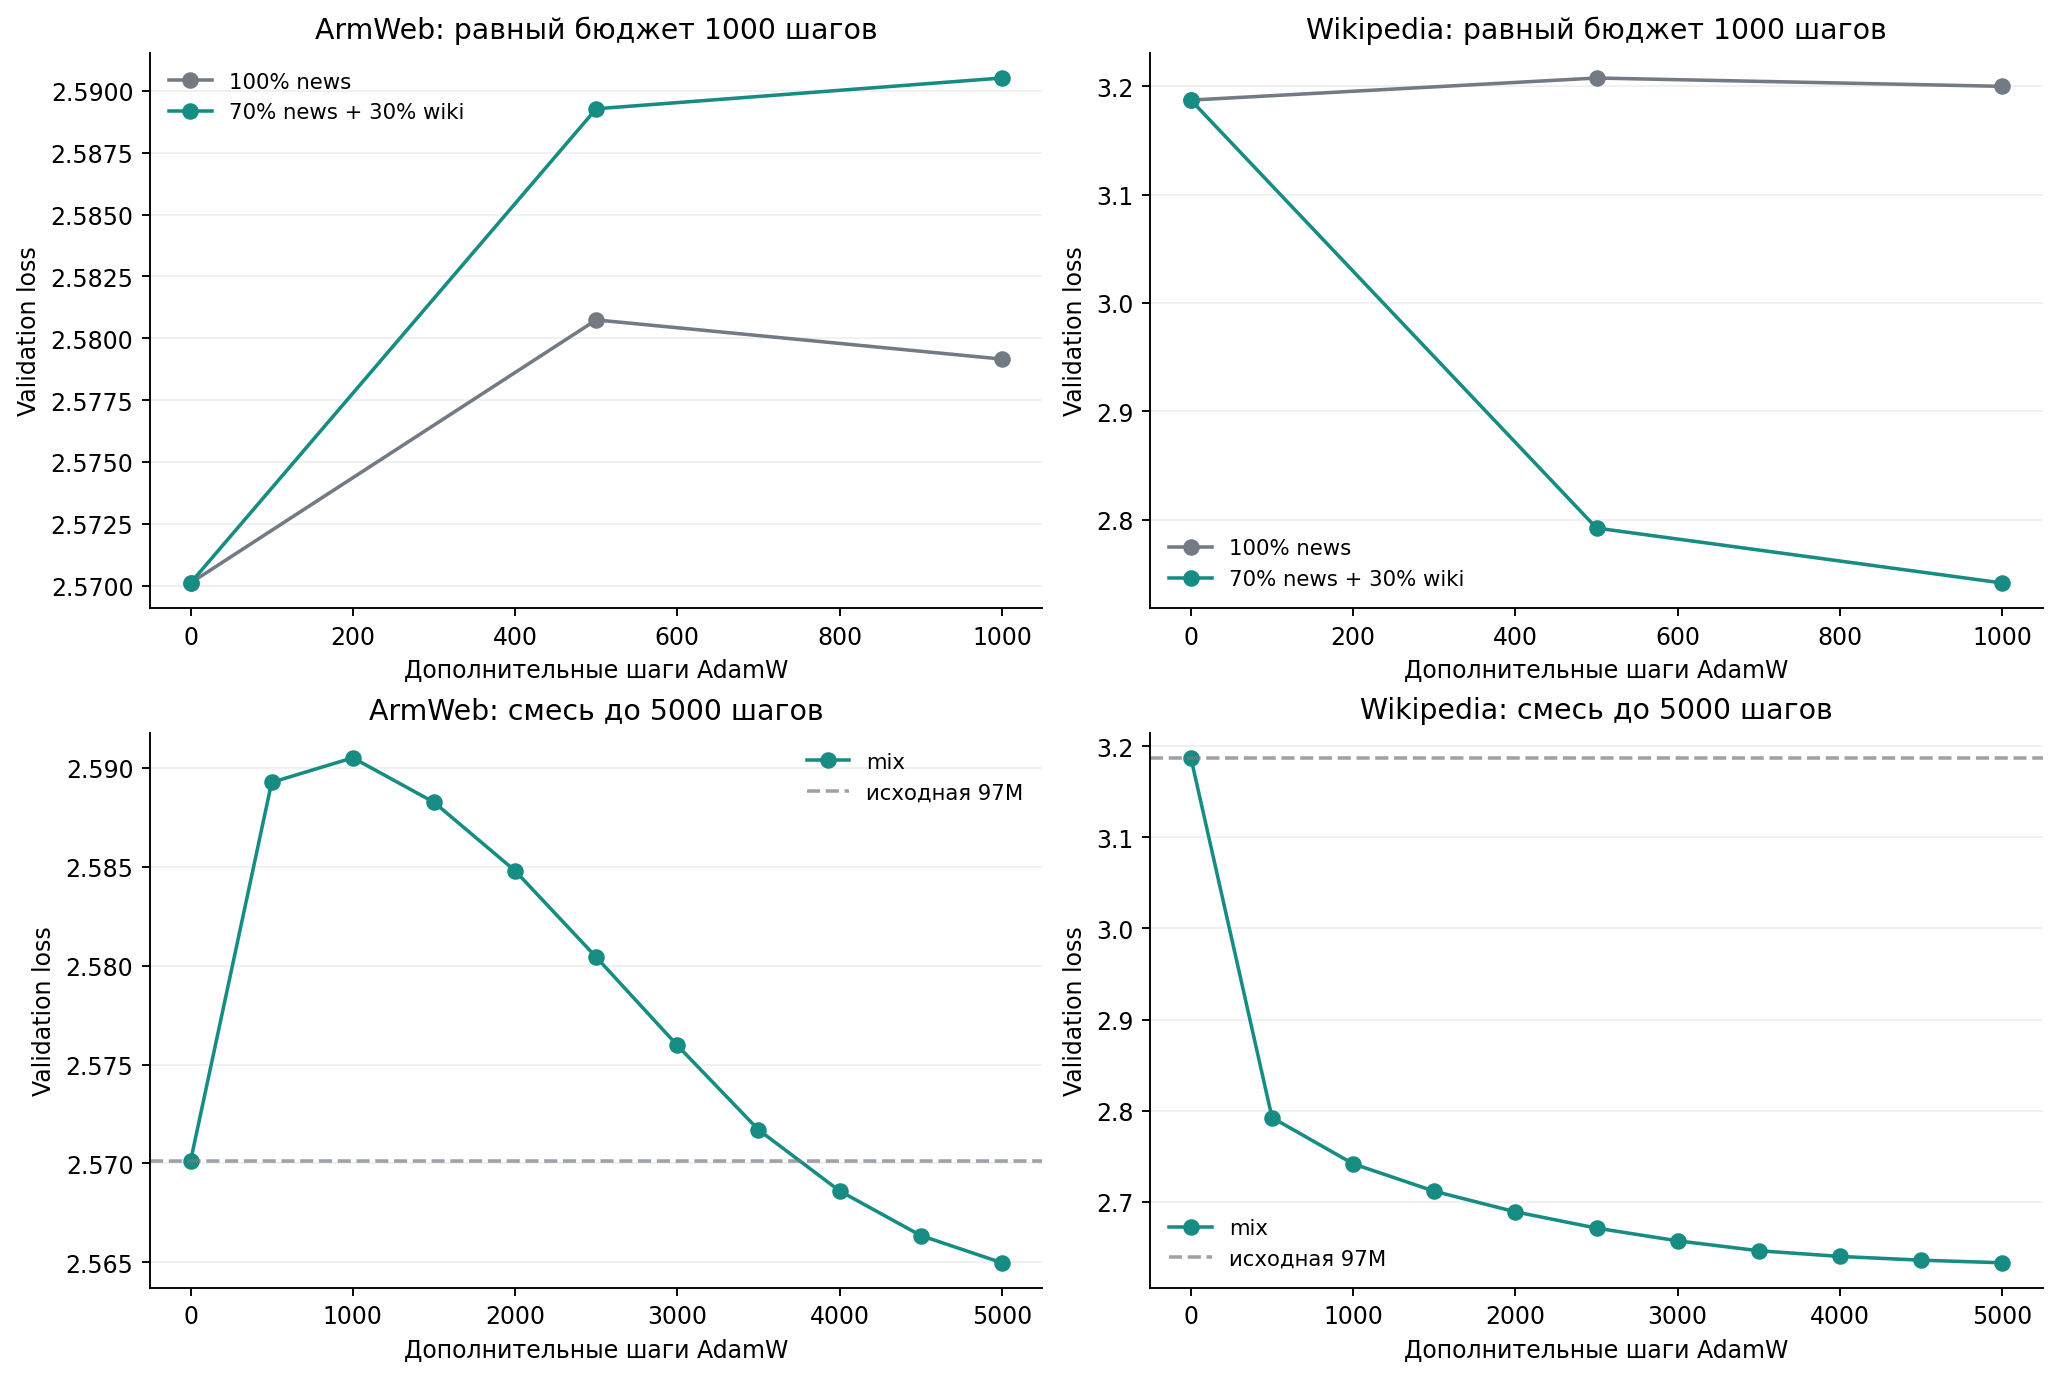

In [5]:
display(Image(filename=str(RESULTS_DIR / 'figures' / '02_data_mixture.png')))

## 5. Отложенные тесты и фактические вопросы

Loss усреднён по всем целевым токенам соответствующего split, с последним коротким остатком; perplexity = exp(loss). Ниже именно test, а не validation.

| Модель | Корпус | Test split | Целевых токенов | Loss | Perplexity |
| --- | --- | --- | --- | --- | --- |
| arm_gpt_35m | armweb | test_iid | 5 560 337 | 2.8964 | 18.11 |
| arm_gpt_35m | armweb | test_tail | 5 820 283 | 2.9041 | 18.25 |
| arm_gpt_97m | armweb | test_iid | 5 560 337 | 2.5819 | 13.22 |
| arm_gpt_97m | armweb | test_tail | 5 820 283 | 2.6042 | 13.52 |
| arm_gpt_97m | wikipedia | test | — | 3.1759 | 23.95 |
| arm_gpt_97m_cpt_mix | armweb | test_iid | — | 2.5771 | 13.16 |
| arm_gpt_97m_cpt_mix | armweb | test_tail | — | 2.5979 | 13.44 |
| arm_gpt_97m_cpt_mix | wikipedia | test | — | 2.5700 | 13.07 |

На отложенной Wikipedia perplexity снизилась с **23.95 до 13.07** (45.4% относительно исходной модели). На обоих тестах ArmWeb есть небольшое улучшение. Checkpoint выбран по validation до этой оценки. Обе 97M оценены на одинаковых test split одним скриптом. Это один запуск; вывод относится к данным корпусам, а не к достоверности свободных фактических ответов.

**Точность записи:** шесть строк финального test прочитаны из сохранённой таблицы outputs в `inference.ipynb`: loss округлён до 4 знаков, perplexity до 2. Для ArmWeb исходных 35M/97M сохранены более точные значения из исходного архива, совпадающие с округлённой таблицей. Прочерки в числе целевых токенов означают, что это число не выведено в таблице ноутбука; оно не восстановлено предположением. Полный JSON финальной оценки и полная кривая 97M не прочитаны, поэтому дополнительные знаки и точки не добавлены.

### Небольшая QA-диагностика

8 фактов × 3 формулировки = 24 связанных вопроса. В MC четыре кандидата; 25% — вероятность случайного выбора среди них. Этот уровень не относится к свободным ответам. Считаются сумма и среднее log-probability токенов ответа; sum может предпочитать более короткие варианты. Свободный ответ оценивается exact match с нормализацией и заданными вариантами, поэтому правильные неучтённые формулировки могут быть пропущены. Два few-shot примера — часть фиксированного промпта, а не SFT.

| Модель | Shots | MC sum /24 | MC mean /24 | Свободный /24 | Все 3 верны MC /8 | Все 3 верны свободно /8 |
| --- | --- | --- | --- | --- | --- | --- |
| 35M | 0 | 15 | 10 | 0 | 5 | 0 |
| 97M | 0 | 14 | 12 | 3 | 4 | 0 |
| 97M + mix | 0 | 17 | 16 | 6 | 4 | 0 |
| 97M + SFT | 0 | 18 | 12 | 0 | 6 | 0 |
| 35M | 2 | 11 | 6 | 0 | 3 | 0 |
| 97M | 2 | 15 | 10 | 2 | 5 | 0 |
| 97M + mix | 2 | 15 | 12 | 2 | 5 | 0 |

В zero-shot после смеси MC sum вырос с 14 до 17, свободные ответы — с 3 до 6. Во всех вариантах **0/8 фактов отвечены свободно верно при всех трёх формулировках**. В two-shot улучшения свободных ответов нет. Факты могли встречаться в претрейне; этот многократно просмотренный маленький набор — диагностика, не независимый бенчмарк общего владения языком и не доказательство статистически значимого улучшения.

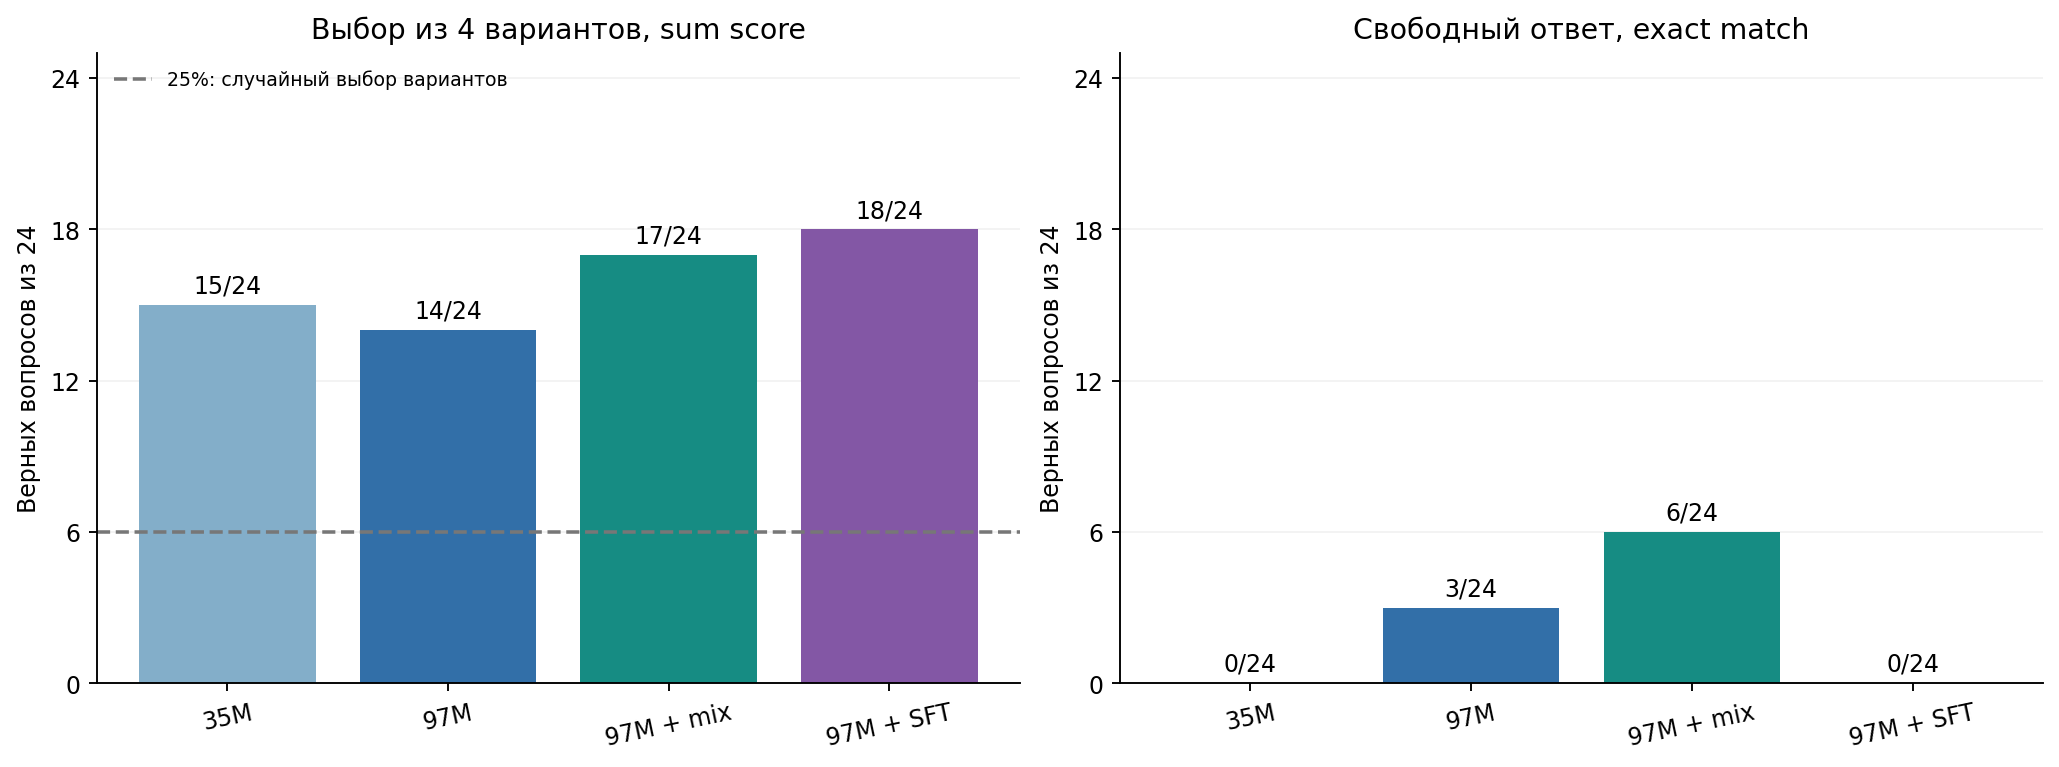

In [6]:
display(Image(filename=str(RESULTS_DIR / 'figures' / '05_qa_zero_shot.png')))

## 6. Эксперимент с SFT

SFT выполнялся на исходной 97M, **до смеси с Wikipedia**. Train — 3136, validation — 391, test — 391 пары Aya/Dolly. Loss считался только по ответу и EOS; prompt и padding маскировались. Лучший checkpoint выбран на шаге 98, а не на последнем шаге 147.

| Модель | Шаг checkpoint | Test пар | Answer loss | Answer perplexity |
| --- | --- | --- | --- | --- |
| arm_gpt_97m | 17 832 | 391 | 3.4145 | 30.40 |
| arm_gpt_97m_sft | 98 | 391 | 3.0038 | 20.16 |

Teacher-forced test loss снизился с **3.4145 до 3.0038**, но свободные ответы в QA-диагностике ухудшились с **3/24 до 0/24**. Эти метрики оценивают разные способности. В данных замечены ошибки перевода и ответов; это возможный фактор, но его причинное влияние отдельным чистым экспериментом не проверялось. Эта SFT-модель не выбрана основной для демонстрации.

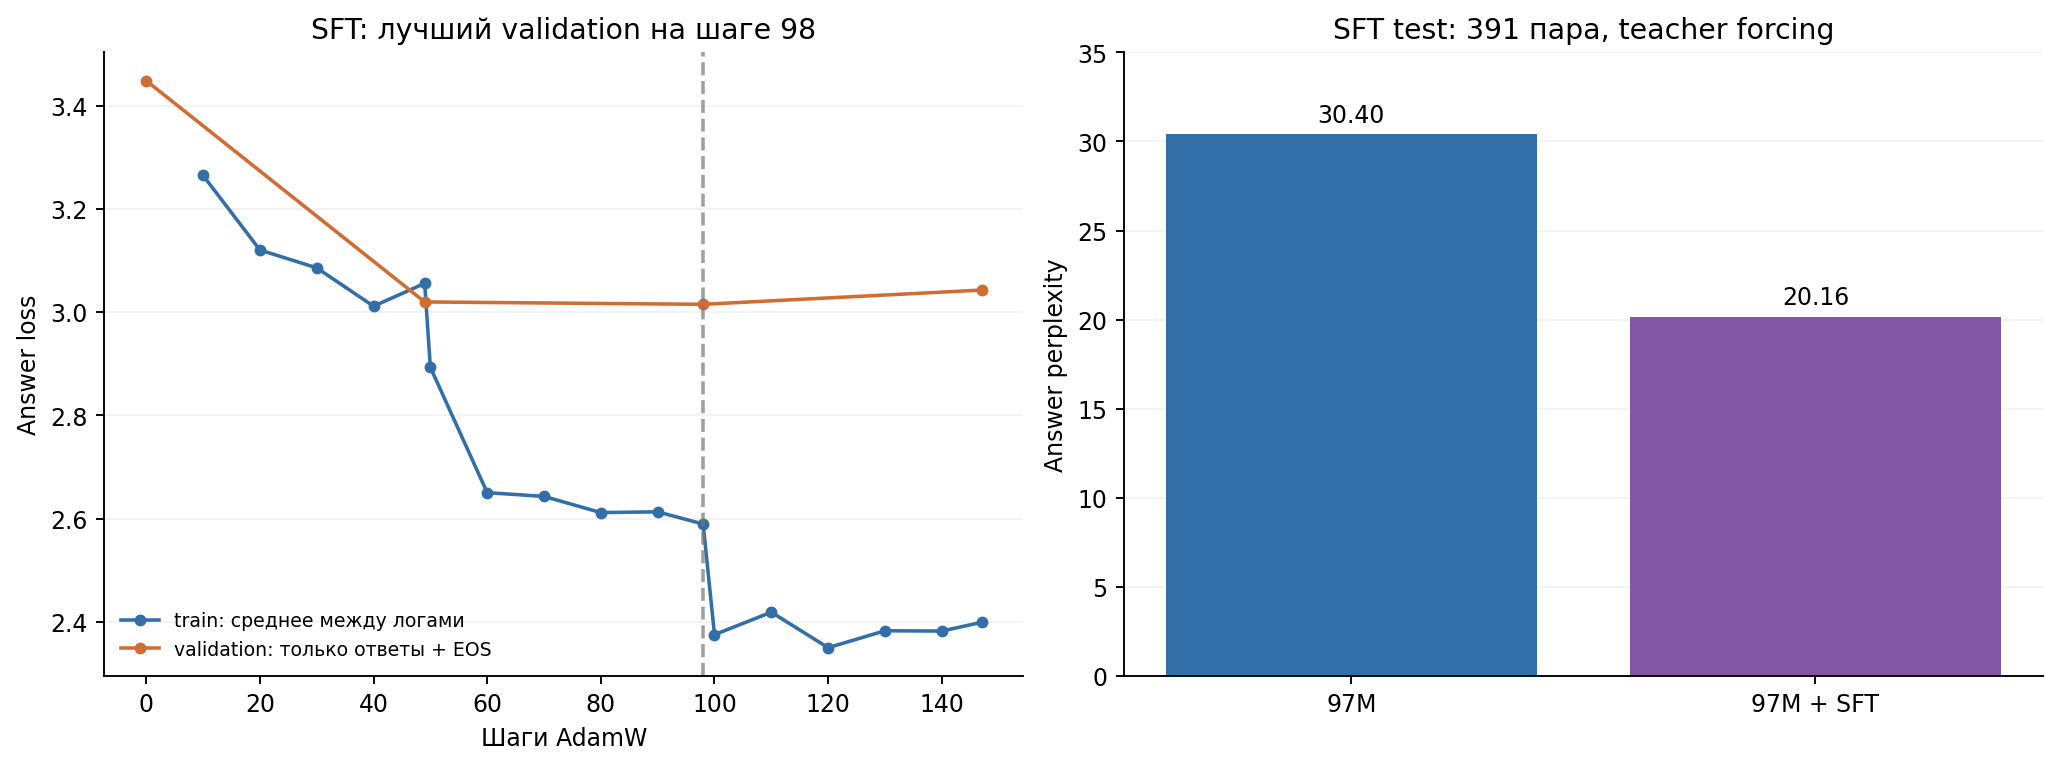

In [7]:
display(Image(filename=str(RESULTS_DIR / 'figures' / '06_sft.png')))

## 7. Инференс и комплект сдачи

В `inference.ipynb` сохранены выводы серверного запуска: выполнено ячеек кода — 7, ошибок в outputs — 0, сохранено примеров — 33. Свободный ответ: **6/24**, все три формулировки верны: **0/8**. Это повтор того же набора, а не новый независимый тест.

Восемь продолжений показывают новостной и энциклопедический стиль, но также повторы и смысловые противоречия. Например, в спортивном продолжении Уэльс побеждает Уэльс; в ответах модель может назвать верный город, а затем повторять вопрос и служебные заголовки. Все примеры оставлены в ноутбуке, без отбора только удачных. Автоматическая оценка грамматики армянского языка не проводилась.

Код data/tokenizer/train, зависимости и инструкции воспроизведения находятся в корне репозитория; токенизатор — в tokenizer/. Для завершения комплекта сдачи остаётся опубликовать checkpoint модели. В отчётах весов нет: manifest исходного экспорта подтверждает только наличие/размеры файлов на сервере. Итоговая оценка test добавлена из таблицы выполненного `inference.ipynb`, с явным указанием округления. 

В конфигурациях обучения указан PyTorch **2.9.1+cu128**, tokenizers **0.22.1**, NumPy **2.4.2**, PyArrow **20.0.0**. В manifest экспорта часть пакетов помечена null — это означает, что их версии не найдены в окружении экспорта. Выполненный notebook подтверждает работу инференса в серверном kernel на момент сохранения.

Полные числовые таблицы, источники и SHA256 прочитанных файлов находятся в `results.json`. Источники — сохранённые файлы и outputs; код из прикреплённых ноутбуков при сборке отчёта не выполняется.